# 25 — Robustness, conformal thresholds, interpretability, latency and adversarial attacks of the CNN

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extensions 5, 6, 30, 32, 34 and 61 on the fresh-injection CNN of notebook 07 (two seeds averaged), with the 160-template bank as reference:

* **5–6 Systematics and robustness.** Observed FAP (at the validation thresholds) and mean efficiency at ρ = 6 (sine-Gaussian, pulse, chirp) under: ±10 % calibration of the signal amplitude; a persistent spectral line left in the noise; whitening with a different PSD estimate (mean instead of median average, 1 s and 16 s Welch segments); signals placed near the window edges (outside the training prior of 0.25–0.75 s).
* **30 Conformal prediction.** Split-conformal threshold for the detection statistic (guaranteed FAP ≤ α if calibration and test noise are exchangeable) calibrated on one set of chunks and checked on others; conformal sets for the 4-class morphology network (coverage and set size against SNR).
* **32 Interpretability.** Input gradients (saliency) of the detection logit on injected sine-Gaussians: fraction of the saliency mass within the signal's duration against the uniform expectation; spectra of the 16 first-layer filters against the injection prior.
* **34 Latency.** Milliseconds per one-second window for the CNN (batch 1 and 1024), the bank and the other networks.
* **61 Adversarial robustness.** FGSM perturbations of the whitened input, in units of the noise σ: efficiency of ρ = 10 signals attacked to hide, and false-alarm rate of noise attacked to alarm.

**What it does not do.** The robustness checks are one-factor-at-a-time perturbations at the nominal thresholds; no retraining with augmentation (extension 60 is in notebook 26); the FGSM attacks are white-box on the CNN and only one step.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import seq_models as sm
import gwosc_tools as g
g.style()
tf, keras, L = sm._tf()
rng = np.random.default_rng(25)
NCH = len(g.chunks()); CH = {i: g.load_chunk(i) for i in range(NCH)}
V, ID = {}, {}
for sp in ("val", "test"): V[sp], ID[sp], _ = g.load_split(sp)
NETS = [sm.train_variant("cnn_fresh", None, None, seed=s, verbose=False)[0] for s in (0, 1)]
logit = lambda v: np.mean([m.predict(sm.clip(v)[..., None], verbose=0, batch_size=1024)[:, 0] for m in NETS], 0)
def bank_stat(v, cid, CHd=CH):
    return g.scan_mixed(v, cid, {c: g.SGBank(CHd[c]["S1"]) for c in np.unique(cid)})["rho2"]
d = np.load(os.path.join(g.CACHE, "scan03_val.npz")); THR = {"bank": g.threshold_at_far(d["rho2"], 1e-2), "cnn": g.threshold_at_far(logit(V["val"]), 1e-2)}
print("thresholds (FAP 1e-2, validation):", THR)

thresholds (FAP 1e-2, validation): {'bank': np.float64(28.484522266387962), 'cnn': np.float32(2.4306228)}


## 5–6. Systematics and robustness

In [2]:
RHO0, NINJ = 6.0, 300
def evaluate(noise, cid, S1, scale=1.0, t0=None, pre=None, chd=CH):
    # observed FAP of the noise at the nominal thresholds, and mean efficiency at RHO0 over the three morphologies (scaled amplitude, optional t0 override)
    out = {}
    nz = pre(noise) if pre else noise
    out["FAP_bank"] = float((bank_stat(nz, cid, chd) > THR["bank"]).mean()); out["FAP_cnn"] = float((logit(nz) > THR["cnn"]).mean())
    eb, ec = [], []
    for kind in g.MORPHS:
        i = rng.choice(len(noise), NINJ, replace=False); p = g.draw_params(kind, rng, NINJ)
        if t0 is not None: p["t0"] = t0(NINJ)
        ser, _, _ = g.inject(noise[i], kind, RHO0 * scale, rng, S1[i], params=p)
        if pre: ser = pre(ser)
        eb.append((bank_stat(ser, cid[i], chd) > THR["bank"]).mean()); ec.append((logit(ser) > THR["cnn"]).mean())
    out["eff_bank"], out["eff_cnn"] = float(np.mean(eb)), float(np.mean(ec)); return out
S1te = np.stack([CH[i]["S1"] for i in ID["test"]]); vt, ct = V["test"], ID["test"]
rows = {"baseline": evaluate(vt, ct, S1te), "signal amplitude x0.9": evaluate(vt, ct, S1te, scale=0.9), "signal amplitude x1.1": evaluate(vt, ct, S1te, scale=1.1)}
def add_line(v, amp, k=60):
    X = g.to_bins(v); ph = np.exp(2j * np.pi * np.random.default_rng(1).uniform(size=len(v))); X[:, k] += amp * ph; return g.to_series(X)
for amp in (3.0, 6.0): rows[f"60 Hz line, norm {amp:g}"] = evaluate(vt, ct, S1te, pre=lambda x, a=amp: add_line(x, a))
rows["injections at window edges (t0 0.03-0.12 / 0.88-0.97)"] = evaluate(vt, ct, S1te, t0=lambda n: np.where(rng.random(n) < .5, rng.uniform(0.03, 0.12, n), rng.uniform(0.88, 0.97, n)))
# alternative whitening PSD estimates: re-whiten the test chunks, thresholds stay those of the baseline
for lab, kw in (("PSD: mean average", dict(average="mean")), ("PSD: 1 s segments", dict(nperseg_s=1.0)), ("PSD: 16 s segments", dict(nperseg_s=16.0))):
    ALT = {i: g.load_chunk(i, psd_kw=kw) for i in g.SPLIT["test"]}; va, ca, _ = g.load_split("test", psd_kw=kw); S1a = np.stack([ALT[i]["S1"] for i in ca])
    chd = dict(CH); chd.update(ALT); rows[lab] = evaluate(va, ca, S1a, chd=chd)
ROB = pd.DataFrame(rows).T; ROB.round(4)

,FAP_bank,FAP_cnn,eff_bank,eff_cnn
baseline,0.0085,0.0038,0.6622,0.8633
signal amplitude x0.9,0.0085,0.0038,0.4900,0.7622
signal amplitude x1.1,0.0085,0.0038,0.8044,0.9356
"60 Hz line, norm 3",0.0085,0.1683,0.6556,0.8667
"60 Hz line, norm 6",0.0085,0.2936,0.6544,0.8778
injections at window edges (t0 0.03-0.12 / 0.88-0.97),0.0085,0.0038,0.0156,0.7389
PSD: mean average,0.0064,0.0035,0.6444,0.8667
PSD: 1 s segments,0.0075,0.0057,0.6578,0.8622
PSD: 16 s segments,0.0097,0.0048,0.6633,0.8633


## 30. Conformal prediction

In [3]:
# detection threshold: split conformal. Calibrate on chunk group A, test on chunk group B (exchangeability across epochs is NOT guaranteed)
def logit_by_chunk():
    full = {}
    for sp in ("val", "test"):
        for c in np.unique(ID[sp]): full[c] = logit(V[sp][ID[sp] == c])
    return full
LG = logit_by_chunk(); BK = {c: bank_stat(V["val" if c in g.SPLIT["val"] else "test"][ID["val" if c in g.SPLIT["val"] else "test"] == c], np.full((ID["val" if c in g.SPLIT["val"] else "test"] == c).sum(), c)) for c in LG}
rows = []
for alpha in (1e-2, 1e-3):
    for (cal, tst) in (([1], [5]), ([5], [1]), ([1, 5], [3, 7]), ([3, 7], [1, 5])):
        for det, D in (("CNN", LG), ("bank", BK)):
            a = np.concatenate([D[c] for c in cal]); n = len(a); k = int(np.ceil((n + 1) * (1 - alpha))); thr = np.sort(a)[min(k, n) - 1]     # conformal quantile (n+1 correction)
            b = np.concatenate([D[c] for c in tst]); rows.append(dict(alpha=alpha, calibration=str(cal), test=str(tst), detector=det, observed=float((b > thr).mean()), ratio=float((b > thr).mean() / alpha)))
CF = pd.DataFrame(rows); print("observed FAP of the conformal threshold; the guarantee (<= alpha on average) needs exchangeable chunks:"); CF.pivot_table(index=["alpha", "calibration", "test"], columns="detector", values="ratio").round(2)

observed FAP of the conformal threshold; the guarantee (<= alpha on average) needs exchangeable chunks:


detector                   CNN  bank
alpha calibration test              
0.001 [1, 5]      [3, 7]  0.86  1.48
      [1]         [5]     0.49  3.45
      [3, 7]      [1, 5]  1.11  0.49
      [5]         [1]     1.48  0.49
0.010 [1, 5]      [3, 7]  0.37  0.85
      [1]         [5]     0.54  1.26
      [3, 7]      [1, 5]  1.96  1.12
      [5]         [1]     1.75  0.69

In [4]:
# conformal sets for the 4-class morphology network (LAC score 1 - p_true), calibrated on validation injections, tested on the test injections of notebooks 05-07
net4 = sm.train_variant("cnn4_fresh", None, None, seed=0, verbose=False)[0]
CHn, data, S1d, DS = sm.load_data(); TEST = sm.make_test_sets(data, S1d)
def probs(x): z = net4.predict(sm.clip(x)[..., None], verbose=0, batch_size=1024); e = np.exp(z - z.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)
yv = DS["val"]["y4"]; Xv = DS["val"]["X"][..., 0]; Pv = probs(Xv); sv = 1 - Pv[np.arange(len(yv)), yv]; alpha = 0.1
qhat = np.sort(sv)[int(np.ceil((len(sv) + 1) * (1 - alpha))) - 1]
rows = []
for (kind, snr), (x, c) in TEST.items():
    P = probs(x); ytrue = sm.KID[kind]; sets = P >= 1 - qhat; rows.append(dict(kind=kind, snr=snr, coverage=float(sets[:, ytrue].mean()), set_size=float(sets.sum(1).mean())))
Pn = probs(data["test"][0]); rows.append(dict(kind="noise", snr=0, coverage=float((Pn >= 1 - qhat)[:, 0].mean()), set_size=float((Pn >= 1 - qhat).sum(1).mean())))
CS = pd.DataFrame(rows); print("target coverage 0.90"); CS.pivot_table(index="snr", columns="kind", values=["coverage", "set_size"]).round(2)

target coverage 0.90


coverage                   set_size                  
kind    chirp noise pulse    sg    chirp noise pulse    sg
snr                                                       
0         NaN  0.98   NaN   NaN      NaN   1.0   NaN   NaN
3        0.08   NaN  0.15  0.07     1.01   NaN  0.99  1.00
4        0.25   NaN  0.42  0.21     1.01   NaN  1.01  1.00
5        0.43   NaN  0.72  0.39     0.99   NaN  1.00  1.00
6        0.74   NaN  0.93  0.69     1.04   NaN  1.02  1.03
7        0.89   NaN  0.98  0.87     1.02   NaN  1.00  1.04
8        0.96   NaN  1.00  0.95     1.01   NaN  1.00  1.03
9        0.97   NaN  1.00  0.97     1.01   NaN  1.00  1.01
10       0.98   NaN  1.00  0.98     1.01   NaN  1.00  1.01
12       0.99   NaN  1.00  1.00     1.00   NaN  1.00  1.00
14       1.00   NaN  1.00  1.00     1.01   NaN  1.00  1.00
16       0.99   NaN  1.00  1.00     1.00   NaN  1.00  1.00

## 32. Interpretability

In [5]:
# saliency of the detection logit of the first network for injected sine-Gaussians at rho = 10
net = NETS[0]; n = 300; i = rng.choice(len(vt), n, replace=False); p = g.draw_params("sg", rng, n); ser, _, _ = g.inject(vt[i], "sg", 10.0, rng, S1te[i], params=p)
x = tf.convert_to_tensor(sm.clip(ser)[..., None])
with tf.GradientTape() as tape:
    tape.watch(x); out = net(x, training=False)
sal = np.abs(tape.gradient(out, x).numpy()[..., 0]) * np.abs(x.numpy()[..., 0])                    # |gradient x input|
t = np.arange(g.NWIN) / g.FS; sigt = p["Q"] / (2 * np.pi * p["f0"]); inside = np.array([sal[j][np.abs(t - p["t0"][j]) < 4 * sigt[j]].sum() / sal[j].sum() for j in range(n)])
frac_win = np.array([(np.abs(t - p["t0"][j]) < 4 * sigt[j]).mean() for j in range(n)])
print("saliency mass inside +-4 sigma_t of the signal: %.2f (uniform expectation %.2f)" % (inside.mean(), frac_win.mean()))
print("peak of saliency within 30 ms of the injected time: %.2f" % np.mean([abs(t[np.argmax(sal[j])] - p["t0"][j]) < 0.03 for j in range(n)]))

saliency mass inside +-4 sigma_t of the signal: 0.30 (uniform expectation 0.10)
peak of saliency within 30 ms of the injected time: 0.75


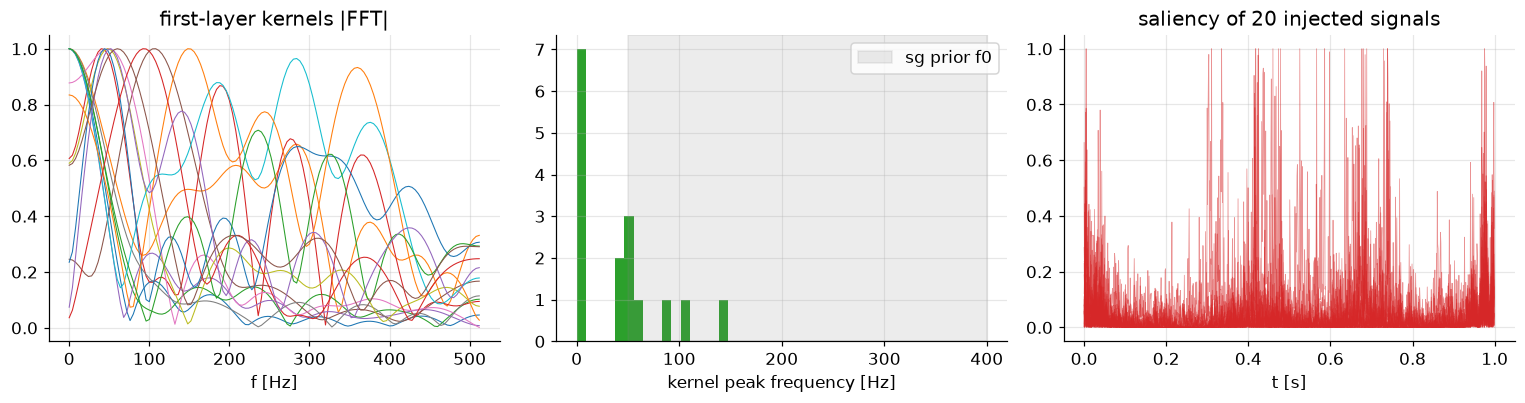

In [6]:
# first-layer filters: peak frequency of each of the 16 kernels (width 15 samples at 1024 Hz)
W = net.layers[0].get_weights()[0][:, 0, :]; F = np.abs(np.fft.rfft(W, n=256, axis=0)); fpk = np.fft.rfftfreq(256, 1 / g.FS)[F.argmax(0)]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].plot(np.fft.rfftfreq(256, 1 / g.FS), F / F.max(0), lw=.7); ax[0].set_xlabel("f [Hz]"); ax[0].set_title("first-layer kernels |FFT|")
ax[1].hist(fpk, bins=16, color=g.COLORS["ml"]); ax[1].axvspan(50, 400, color="grey", alpha=.15, label="sg prior f0"); ax[1].set_xlabel("kernel peak frequency [Hz]"); ax[1].legend()
ax[2].plot(t, (sal[:20] / sal[:20].max(1)[:, None]).T, lw=.5, color=g.COLORS["bayes"], alpha=.5); ax[2].set_xlabel("t [s]"); ax[2].set_title("saliency of 20 injected signals")
fig.tight_layout(); g.savefig(fig, "fig25_interpretability"); plt.show()

## 34. Latency

In [7]:
def timeit(f, reps=5):
    f(); t0_ = time.perf_counter()
    for _ in range(reps): f()
    return (time.perf_counter() - t0_) / reps
x1 = sm.clip(V["test"][:1])[..., None]; x1k = sm.clip(V["test"][:1024])[..., None]; bk = g.SGBank(CH[3]["S1"])
tf16 = sm.train_variant("tf16_fresh", None, None, seed=0, verbose=False)[0]; hy = sm.train_variant("hyb_fresh", None, None, seed=0, verbose=False)[0]
rows = [dict(model="CNN (17.8 k)", ms_per_window_batch1=1e3 * timeit(lambda: NETS[0].predict(x1, verbose=0)), ms_per_window_batch1024=1e3 * timeit(lambda: NETS[0].predict(x1k, verbose=0, batch_size=1024), 3) / 1024),
        dict(model="hybrid", ms_per_window_batch1=1e3 * timeit(lambda: hy.predict(x1, verbose=0)), ms_per_window_batch1024=1e3 * timeit(lambda: hy.predict(x1k, verbose=0, batch_size=1024), 3) / 1024),
        dict(model="Transformer", ms_per_window_batch1=1e3 * timeit(lambda: tf16.predict(x1, verbose=0)), ms_per_window_batch1024=1e3 * timeit(lambda: tf16.predict(x1k, verbose=0, batch_size=1024), 3) / 1024),
        dict(model="bank (160 templates, numpy FFT)", ms_per_window_batch1=1e3 * timeit(lambda: bk.scan(g.to_bins(V["test"][:1]))), ms_per_window_batch1024=1e3 * timeit(lambda: bk.scan(g.to_bins(V["test"][:256])), 2) / 256)]
LAT = pd.DataFrame(rows).set_index("model"); LAT.round(3)

,ms_per_window_batch1,ms_per_window_batch1024
model,,
CNN (17.8 k),88.122,0.170
hybrid,138.845,1.927
Transformer,143.367,1.040
"bank (160 templates, numpy FFT)",4.268,3.455


## 61. Adversarial perturbations (FGSM)

In [8]:
def grad_sign(x):
    xt = tf.convert_to_tensor(x[..., None])
    with tf.GradientTape() as tape:
        tape.watch(xt); out = NETS[0](xt, training=False)
    return np.sign(tape.gradient(out, xt).numpy()[..., 0])
n = 1000; i = rng.choice(len(vt), n, replace=False); ser = np.concatenate([g.inject(vt[i[a::3]], k, 10.0, rng, S1te[i[a::3]])[0] for a, k in enumerate(g.MORPHS)]); cs = np.concatenate([ct[i[a::3]] for a in range(3)])
nz = vt[rng.choice(len(vt), n, replace=False)]; cn = ct[rng.choice(len(vt), n, replace=False)]
gs = grad_sign(sm.clip(ser)); gn = grad_sign(sm.clip(nz)); rows = []
for eps in (0.0, 0.05, 0.1, 0.2, 0.4):
    hide = ser - eps * gs; alarm = nz + eps * gn
    rows.append(dict(eps_sigma=eps, perturbation_norm=eps * np.sqrt(g.NWIN), eff_cnn_rho10_attacked=float((logit(hide) > THR["cnn"]).mean()), eff_bank_same_perturbation=float((bank_stat(hide, cs) > THR["bank"]).mean()),
                     FAP_cnn_attacked=float((logit(alarm) > THR["cnn"]).mean()), FAP_bank_same_perturbation=float((bank_stat(alarm, cn) > THR["bank"]).mean())))
ADV = pd.DataFrame(rows).set_index("eps_sigma"); ADV.round(3)

,perturbation_norm,eff_cnn_rho10_attacked,eff_bank_same_perturbation,FAP_cnn_attacked,FAP_bank_same_perturbation
eps_sigma,,,,,
0.00,0.0,0.999,0.999,0.005,0.009
0.05,1.6,0.830,0.999,0.071,0.014
0.10,3.2,0.330,0.998,0.057,0.021
0.20,6.4,0.022,0.993,0.000,0.056
0.40,12.8,0.000,0.984,0.000,0.231


In [9]:
g.save_json(dict(robustness=ROB.reset_index().to_dict("records"), conformal_detection=CF.to_dict("records"), conformal_sets=CS.to_dict("records"), saliency=dict(mass_inside=float(inside.mean()), uniform=float(frac_win.mean())),
                 latency=LAT.reset_index().to_dict("records"), adversarial=ADV.reset_index().to_dict("records")), "25_summary.json"); print("saved")

saved


## Output and next step

`results/25_summary.json`, `figures/fig25_interpretability`. Next: augmentation, scaling laws and domain adaptation (extensions 60, 62, 28).